Loading dataset...
Training the SVM (RBF) Pipeline...

 Model Training Complete in 0.50s!
Accuracy on test data: 98.10%

Detailed Report:
              precision    recall  f1-score   support

        Drag       0.97      0.99      0.98       343
  Left_Click       0.97      1.00      0.98       308
        Move       0.98      0.97      0.98       438
     Neutral       0.99      0.93      0.96       239
 Right_Click       1.00      0.99      0.99       325
      Scroll       0.99      1.00      1.00       349

    accuracy                           0.98      2002
   macro avg       0.98      0.98      0.98      2002
weighted avg       0.98      0.98      0.98      2002

Single prediction latency: 0.468 ms


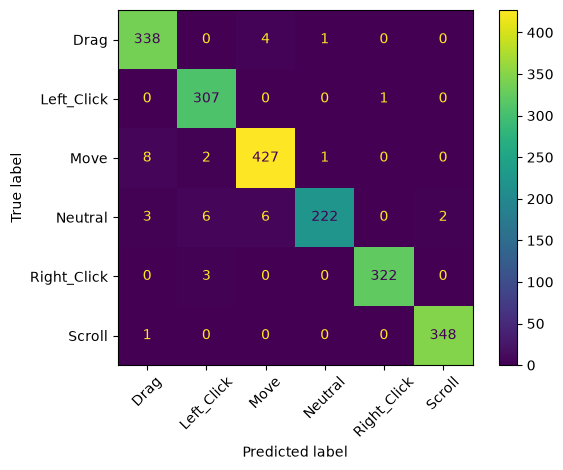

Brain saved successfully as 'd:\My Codes\Projects\AI\Virtual Mouse\Virtual Mouse\Model_Training\virtual_mouse_brain.pkl'


In [ ]:
import os
import sys
import time
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

current_dir = os.getcwd()
sys.path.append(os.path.abspath(os.path.join(current_dir, "../..")))

csv_path = os.path.abspath(
    os.path.join(
        current_dir, "..", "Data_Engineering", "Dataset", "virtual_mouse_data.csv"
    )
)

print("Loading dataset...")
df = pd.read_csv(csv_path)

X = df.drop("gesture_label", axis=1).values
y = df["gesture_label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y # طبقي
)

print("Training the SVM (RBF) Pipeline...")
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10.0, random_state=42))
])

train_start = time.perf_counter() # time
model.fit(X_train, y_train)
train_time = time.perf_counter() - train_start

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n Model Training Complete in {train_time:.2f}s!")
print(f"Accuracy on test data: {accuracy * 100:.2f}%\n")
print("Detailed Report:")
print(classification_report(y_test, y_pred))

single_sample = X_test[0:1]
_ = model.predict(single_sample)  

lat_start = time.perf_counter()
for _ in range(100):
    _ = model.predict(single_sample)
avg_latency_ms = ((time.perf_counter() - lat_start) / 100) * 1000

print(f"Single prediction latency: {avg_latency_ms:.3f} ms")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="viridis")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

model_filename = os.path.join(current_dir, "virtual_mouse_brain.pkl")
with open(model_filename, "wb") as f:
    pickle.dump(model, f)

print(f"Brain saved successfully as '{model_filename}'")

In [3]:
import os
import sys
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

current_dir = os.getcwd()
csv_path = os.path.abspath(
    os.path.join(current_dir, "..", "Data_Engineering", "Dataset", "virtual_mouse_data.csv")
)

print(f"Loading dataset from: {csv_path}")
df = pd.read_csv(csv_path)

X = df.drop("gesture_label", axis=1).values
y = df["gesture_label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    
    "Support Vector Machine (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=10.0, random_state=42))
    ]),
    
    "Neural Network (MLP)": Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42))
    ])
}

results = []

single_sample = X_test[0:1]

for name, model in models.items():
    print(f"\n==================== Training {name} ====================")
    
    train_start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - train_start
    
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    _ = model.predict(single_sample) 
    lat_start = time.perf_counter()
    for _ in range(100):
        _ = model.predict(single_sample)
    avg_latency_ms = ((time.perf_counter() - lat_start) / 100) * 1000
    
    print(f"Accuracy: {acc * 100:.2f}%")
    print(f"Training Time: {train_time:.2f} s")
    print(f"Single Prediction Latency: {avg_latency_ms:.3f} ms")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    results.append({
        "Algorithm": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Latency (ms)": round(avg_latency_ms, 3),
        "Training Time (s)": round(train_time, 2)
    })
    
    fig, ax = plt.subplots(figsize=(6, 5))
    cm = confusion_matrix(y_test, y_pred)
    classes = np.unique(y)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap="viridis", xticks_rotation=45)
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.savefig(f"confusion_matrix_{name.replace(' ', '_')}.png")
    plt.close()

summary_df = pd.DataFrame(results)
print("\n==================== Summary Comparison ====================")
print(summary_df.to_string(index=False))

Loading dataset from: d:\My Codes\Projects\AI\Virtual Mouse\Virtual Mouse\Data_Engineering\Dataset\virtual_mouse_data.csv

==================== Training Random Forest ====================
Accuracy: 97.35%
Training Time: 3.37 s
Single Prediction Latency: 6.782 ms

Classification Report:
              precision    recall  f1-score   support

        Drag       0.96      0.98      0.97       343
  Left_Click       0.97      0.99      0.98       308
        Move       0.97      0.97      0.97       438
     Neutral       0.97      0.88      0.93       239
 Right_Click       0.99      0.99      0.99       325
      Scroll       0.98      1.00      0.99       349

    accuracy                           0.97      2002
   macro avg       0.97      0.97      0.97      2002
weighted avg       0.97      0.97      0.97      2002


==================== Training Support Vector Machine (RBF) ====================
Accuracy: 98.10%
Training Time: 0.47 s
Single Prediction Latency: 0.471 ms

Classificatio

In [7]:
print(summary_df.to_string(index=False))

                   Algorithm  Accuracy (%)  Latency (ms)  Training Time (s)
               Random Forest         97.60         7.028               3.33
Support Vector Machine (RBF)         98.10         0.466               0.46
        Neural Network (MLP)         98.25         0.440              11.34
